In [1]:
#cell that have all of the imports
# Data
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# pytorch
import torch
import torch.nn.functional as F
from torch import nn, tensor
from torch.utils.data import DataLoader, Dataset

# torchvision
from torchvision import transforms, models
from torchvision.transforms import functional as TF

# fastai
from fastai.vision.all import *
from fastai.tabular.all import *
from fastai.data.transforms import RandomSplitter
from fastai.callback.hook import *

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
set_seed(42)

In [3]:
# we are going to get some Data here of movies (small 100k)
path = untar_data(URLs.ML_100k)

In [4]:
# this Is the Data that is for the ratings (There is other two, one for customers and one for movies).
ratings = pd.read_csv(path/'u.Data',
                      delimiter='\t', # the seperator in this csv is the TAB e.g --> 1  2  3
                      header=None, # there is no headers in the file so we are going to make ones ourselves
                      names=['user', 'movie', 'rating', 'timestamp'])

ratings.head()

,user,movie,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [5]:
# how it works
movie = np.array([0.98,0.9,-0.9])
user = np.array([0.9,0.8,-0.6])
(user*movie).sum().item() # the match (Rating)

2.1420000000000003

* u.data   → the ratings table (what you just loaded) --- user, movie, rating, timestamp
* u.item   → movie info ----- movie_id, title, release_date, ...
* u.user   → user info --- user_id, age, gender, occupation, ...

In [6]:
# load the u.item
movies = pd.read_csv(path/"u.item",
                     delimiter='|',
                     header=None,
                     encoding='latin-1',# the file has special characters (accents, symbols in movie names) -- latin-1 handles those, default utf-8 would crash
                     usecols=[0,1],# u.item has many columns but we only need the first two (0 = movie_id, 1 = title, rest is release date, url, genres etc)
                     names=['movie', 'title'])
movies.head()

,movie,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [7]:
movies[movies["movie"]==51]

,movie,title
50,51,Legends of the Fall (1994)


In [8]:
# merge it with the rating table
ratings = ratings.merge(movies)
ratings.head()

,user,movie,rating,timestamp,title
0,196,242,3,881250949,Kolya (1996)
1,186,302,3,891717742,L.A. Confidential (1997)
2,22,377,1,878887116,Heavyweights (1994)
3,244,51,2,880606923,Legends of the Fall (1994)
4,166,346,1,886397596,Jackie Brown (1997)


In [9]:
from fastai.collab import CollabDataLoaders

# make dataloaders
dls = CollabDataLoaders.from_df(ratings, item_name='title', bs=64)
dls.show_batch()

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/fastai/torch_core.py:154: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:203.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


,user,title,rating
0,782,Starship Troopers (1997),2
1,943,Judge Dredd (1995),3
2,758,Mission: Impossible (1996),4
3,94,Farewell My Concubine (1993),5
4,23,Psycho (1960),4
5,296,Secrets & Lies (1996),5
6,940,"American President, The (1995)",4
7,334,Star Trek VI: The Undiscovered Country (1991),1
8,380,Braveheart (1995),4
9,690,So I Married an Axe Murderer (1993),1


torch.rand(3)    # → uniform distribution, numbers between 0 and 1
                 # [0.1, 0.7, 0.4]

torch.randn(3)   # → normal distribution, mean=0, std=1
                 # can be negative, most values between -3 and 3
                 # [-0.5, 1.2, -2.1]

In [10]:
# make the movie and user factors
n_users = len(dls.classes['user'])
n_movies = len(dls.classes['title'])
n_factors = 5

user_factors = torch.randn(n_users, n_factors)
movie_factors = torch.randn(n_movies, n_factors)

In [11]:
# One hot encoding is a way to look up indexes by using the math. Matrix multiplication. But it's slow. And we use embedding instead.
one_hot_1 = one_hot(3,n_users).float()
one_hot_1[:10]

tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])

In [12]:
user_factors.t() @ one_hot_1

tensor([-0.4586, -0.9915, -0.4052, -0.3621, -0.5908])

In [13]:
user_factors[3]

tensor([-0.4586, -0.9915, -0.4052, -0.3621, -0.5908])

So inheritance in a class, let's take pytorch for example. Instead of us writing all the functions the class, we take functions that are already written, So we take it already written at our current class. So it's about extra functions for our class.

In [14]:
# make a class that inherit from nn.Module
class DotProduct(nn.Module):
    def __init__(self,n_users,n_movies,n_factors):
        super().__init__()
        self.user_factors = nn.Embedding(n_users, n_factors)
        self.movies_factors = nn.Embedding(n_movies, n_factors)
    def forward(self, x): # x is one batch — a table of (user_id, movie_id) pairs:(: is for all batch rows
        users = self.user_factors(x[:,0])
        movies = self.movies_factors(x[:,1])
        return (users*movies).sum(dim=1) # dim=1 is becasue the dim=0 is the batch

`nn.Module` watches every `self.` assignment. When it sees you assigned an `nn.Embedding` or any `nn.` object, it automatically registers it as a parameter to track.
```
self.user_factors  = nn.Embedding(...)  → tracked ✓
self.movie_factors = nn.Embedding(...)  → tracked ✓
self.name          = "hello"            → NOT tracked, just a string

In [15]:
5e-3

0.005

In [16]:
# make and train the model
model = DotProduct(n_users, n_movies, 50)
learn = Learner(dls, model,loss_func=MSELossFlat())
learn.fit_one_cycle(5,5e-3)

epoch,train_loss,valid_loss,time
0,42.257782,47.533630,00:05
1,17.489231,27.276447,00:04
2,6.844040,14.761750,00:04
3,3.706197,10.419333,00:05
4,3.468353,9.888795,00:04


### to make the model better we are going to make *'sigmoid range' (0 --> 5,5)  [to be able to get 5 we make the limit slightly higher]*

In [17]:
class DotProduct(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0,5.5)):
        self.user_factors = Embedding(n_users, n_factors)
        self.movie_factors = Embedding(n_movies, n_factors)
        self.y_range = y_range

    def forward(self, x):
        users = self.user_factors(x[:,0])
        movies = self.movie_factors(x[:,1])
        return sigmoid_range((users * movies).sum(dim=1), *self.y_range) # sigmoid_range(result, 0, 5.5)

In [18]:
model = DotProduct(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time
0,0.941521,0.994588,00:04
1,0.670781,0.938381,00:04
2,0.452434,0.937510,00:04
3,0.369067,0.941360,00:05
4,0.335665,0.938803,00:05


We are going to add bias. Bias is like if we have a user that rates all of the movies he watch by five stars, his bias is gonna be high, or god father movie is universally highly rated so it's gonna have a high bias and vice versa low rating a lot of times low bias that is just me to me place for repetition of the mind of the reader.

and from important features of it is it's not in the multiplication so it is constant

In [19]:
class DotProductBias(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0,5.5)):
        self.user_factors = Embedding(n_users, n_factors)
        self.user_bias = Embedding(n_users, 1)
        self.movie_factors = Embedding(n_movies, n_factors)
        self.movie_bias = Embedding(n_movies, 1)
        self.y_range = y_range

    def forward(self, x):
        users = self.user_factors(x[:,0])
        movies = self.movie_factors(x[:,1])
        res = (users * movies).sum(dim=1, keepdim=True) # becasue we are going to add the bias which has dim as [number_users , bias] so we need to make the res [[1.2],...] and not [1.2,...] so that the addition happens
        res += self.user_bias(x[:,0]) + self.movie_bias(x[:,1]) # add the bias
        return sigmoid_range(res, *self.y_range)

In [20]:
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time
0,0.896085,0.936565,00:05
1,0.585419,0.907368,00:06
2,0.384846,0.936854,00:05
3,0.321342,0.954459,00:05
4,0.305880,0.954198,00:06


looks like the model is overfitting

## **Weight Decay**

    WAY 1 — add penalty to loss (slow):
    loss_with_wd = loss + wd * (parameters**2).sum()

    # this means:
    # 1. square every single weight
    # 2. sum them all up (millions of weights)
    # 3. add to loss
    # 4. THEN backprop through all of it
    # expensive and slow
--

    WAY 2 — just tweak the gradients directly (fast):
    parameters.grad += wd * 2 * parameters

    FOR HOW IS THIS THE SAME:

    -total_loss = (p - y)²  +  wd * w²

    -d(total_loss)/dw = d[(p-y)²]/dw  +  d[wd*w²]/dw

    -total gradient:
    d(total_loss)/dw = -3.2 + 0.24 = -2.96

    -update:
    w = 1.2 - lr * (-2.96) = 1.2 + 0.0296  ← still goes up but less aggressively

    # skip the big sum entirely
    # just directly add to the gradients
    # same mathematical effect
    # much faster

In [21]:
# make the model with the weight decay (just pass the wd for fast ai fucntion) [we saw the math]
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time
0,0.906639,0.946161,00:06
1,0.684602,0.893279,00:05
2,0.525380,0.880381,00:05
3,0.465558,0.863566,00:06
4,0.439729,0.860790,00:06


# Making our own embedding module

In [22]:
# make a class of torch ones and it wont be trackable because it is not in the nn.Parameter()
class T(Module):
    def __init__(self): self.a = torch.ones(3)

L(T().parameters()) # L is from fast ai to make a list

[]

there is no trackable parems because it is not in the nn.Parameter()

In [23]:
# now put it in nn.Parameter()
class T(Module):
    def __init__(self): self.a = nn.Parameter(torch.ones(3))

L(T().parameters())

[Parameter containing:
tensor([1., 1., 1.], requires_grad=True)]

In [24]:
# any like nn.Embedding or nn.Linear etc also tell pytorch that those are params
class T(Module):
    def __init__(self): self.a = nn.Linear(1, 3, bias=False) # those are the dim=[1,3]
t = T()
L(t.parameters())

[Parameter containing:
tensor([[0.7954],
        [0.8461],
        [0.3979]], requires_grad=True)]

In [25]:
type(t.a)

torch.nn.modules.linear.Linear

In [26]:
type(t.a.weight)

torch.nn.parameter.Parameter

In [27]:
# lets make a function that makes params
def create_params (size:list):
    return nn.Parameter(torch.zeros(*size).normal_(0,0.01))# the normal makes use able to control the mean=0 (around zero as the middle ground) and std=0.01 (std controls HOW SPREAD OUT the numbers are 0.01 makes almost all between -0.03 and 0.03) , we didnt use the torch.randn because it doesnt allow for this control in params
     # we use normal_() instead of randn because
        # randn defaults to std=1 which is too large
        # and causes unstable training

In [28]:
# lets make the model with it
class DotProductBias(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0,5.5)):
        self.user_factors = create_params([n_users, n_factors])
        self.user_bias = create_params([n_users])
        self.movie_factors = create_params([n_movies, n_factors])
        self.movie_bias = create_params([n_movies])
        self.y_range = y_range

    def forward(self, x):
        users = self.user_factors[x[:,0]]
        movies = self.movie_factors[x[:,1]]
        res = (users*movies).sum(dim=1)
        res += self.user_bias[x[:,0]] + self.movie_bias[x[:,1]]
        return sigmoid_range(res, *self.y_range)

In [29]:
# lets train
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time
0,0.880089,0.948447,00:06
1,0.662175,0.897515,00:06
2,0.546670,0.869582,00:06
3,0.446721,0.858456,00:05
4,0.450270,0.852973,00:05


# Interpreting Embeddings and Biases

In [30]:
# now we can see what are the worst movies ( by using the bias)
movie_biases = learn.model.movie_bias
movie_biases.shape

torch.Size([1638])

In [31]:
# just in case for safety
movie_biases = movie_biases.squeeze()
movie_biases.shape

torch.Size([1638])

In [32]:
bad_idxs   = movie_biases.argsort()[:10]
good_idxs = movie_biases.argsort(descending=True)[:10]

In [33]:
# bad
[dls.classes['title'][i] for i in bad_idxs ]

['Lawnmower Man 2: Beyond Cyberspace (1996)',
 'Children of the Corn: The Gathering (1996)',
 'Showgirls (1995)',
 'Island of Dr. Moreau, The (1996)',
 'Grease 2 (1982)',
 'Robocop 3 (1993)',
 'Beautician and the Beast, The (1997)',
 'Addiction, The (1995)',
 'Leave It to Beaver (1997)',
 'Spice World (1997)']

In [34]:
# good
[dls.classes['title'][i.item()] for i in good_idxs ]

['Shawshank Redemption, The (1994)',
 "Schindler's List (1993)",
 'Titanic (1997)',
 'Good Will Hunting (1997)',
 'Rear Window (1954)',
 'Henry V (1989)',
 'Casablanca (1942)',
 'Boot, Das (1981)',
 'L.A. Confidential (1997)',
 'Star Wars (1977)']

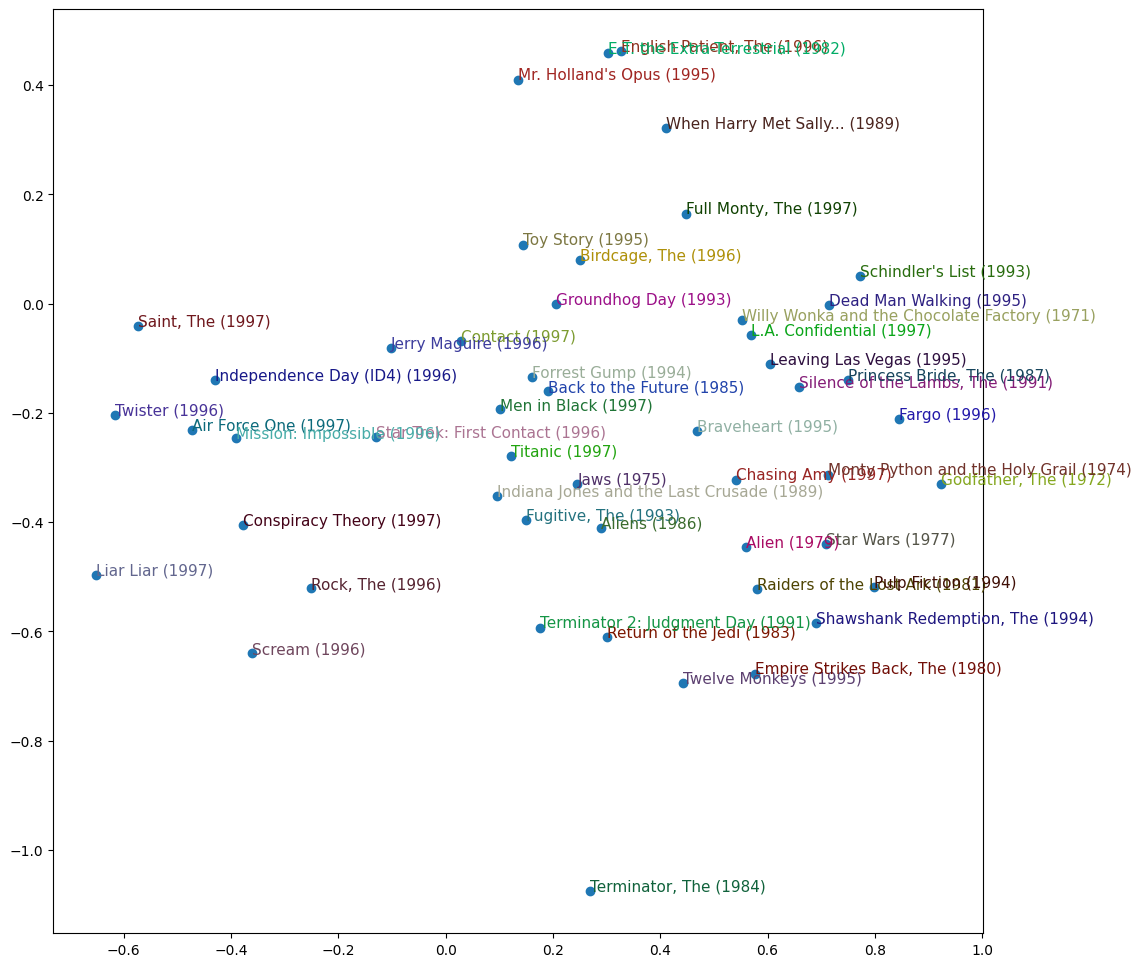

In [35]:
# now make a PCA plot that compress all of the 50 features to 3 features ( just understand the concept of PCA )
g = ratings.groupby('title')['rating'].count()
top_movies = g.sort_values(ascending=False).index.values[:1000]
top_idxs = tensor([learn.dls.classes['title'].o2i[m] for m in top_movies])
movie_w = learn.model.movie_factors[top_idxs].cpu().detach()
movie_pca = movie_w.pca(3)
fac0,fac1,fac2 = movie_pca.t()
idxs = list(range(50))
X = fac0[idxs]
Y = fac2[idxs]
plt.figure(figsize=(12,12))
plt.scatter(X, Y)
for i, x, y in zip(top_movies[idxs], X, Y):
    plt.text(x,y,i, color=np.random.rand(3)*0.7, fontsize=11)
plt.show()

# make all this in instant using the fast ai

In [36]:
from fastai.collab import collab_learner

learn = collab_learner(dls, n_factors=50, y_range=(0, 5.5))
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time
0,0.911634,0.931960,00:05
1,0.641864,0.888913,00:05
2,0.529746,0.871170,00:05
3,0.476558,0.854360,00:05
4,0.431198,0.849702,00:05


In [37]:
# check the names of layers in the model
learn.model

EmbeddingDotBias(
  (u_weight): Embedding(944, 50)
  (i_weight): Embedding(1638, 50)
  (u_bias): Embedding(944, 1)
  (i_bias): Embedding(1638, 1)
)

In [38]:
# we can also see the best movies
movie_bias = learn.model.i_bias.weight.squeeze()
idxs = movie_bias.argsort(descending=True)[:5]
[dls.classes['title'][i] for i in idxs]

['Titanic (1997)',
 'Shawshank Redemption, The (1994)',
 'Rear Window (1954)',
 'Good Will Hunting (1997)',
 "Schindler's List (1993)"]

what needed from the code below:

    ## 1
    Similar movies = similar embedding vectors.
    Silence of the Lambs  → [0.3, -0.1, 0.8, 0.5, ...]
    Seven                 → [0.3, -0.1, 0.7, 0.5, ...]  ← close → similar
    Titanic               → [-0.2, 0.9, 0.1, -0.3, ...] ← far → different
--

    ## 2
    similar movies = similar vectors ← always true
    how you measure similarity ← cosine(angle between them) or euclidean, both work

In [39]:
movie_factors = learn.model.i_weight.weight # i --> item (movie)
idx = dls.classes['title'].o2i['Silence of the Lambs, The (1991)']
distances = nn.CosineSimilarity(dim=1)(movie_factors, movie_factors[idx][None])
idx = distances.argsort(descending=True)[1]
dls.classes['title'][idx]

'My Man Godfrey (1936)'

# making a collab_filtering model using the NN

In [40]:
# use a fast_ai function to get teh recommended embedding size (only for the NN version)
embds = get_emb_sz(dls)
embds

[(944, 74), (1638, 101)]

In [41]:
# making the NN class
class collabNN (Module):
    def __init__(self,n_users,n_movies,n_activations=100,y_range=(0,5.5)):
        self.user_factors = Embedding(*n_users)
        self.movie_factors = Embedding(*n_movies)
        # make the NN layer
        self.NN_layers = nn.Sequential(
            nn.Linear(n_users[1]+n_movies[1],n_activations),
            nn.ReLU(),
            nn.Linear(n_activations,1)
        )
        self.y_range = y_range
    def forward(self,x):
        embs = self.user_factors(x[:,0]),self.movie_factors(x[:,1])
        x = self.NN_layers(torch.cat(embs, dim=1)) # cat glues them together
        return sigmoid_range(x, *self.y_range)

In [42]:
# make the model
model = collabNN(*embds)

In [43]:
# train
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.01)

epoch,train_loss,valid_loss,time
0,0.931578,0.947459,00:06
1,0.865058,0.909738,00:05
2,0.823228,0.887377,00:06
3,0.773153,0.876582,00:06
4,0.791759,0.869281,00:06


In [44]:
# use the ready fast_ai for making the same result
learn = collab_learner(dls, use_nn=True, y_range=(0, 5.5), layers=[100,50])
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time
0,0.964798,0.989936,00:06
1,0.897144,0.913003,00:06
2,0.846846,0.886372,00:06
3,0.759664,0.864168,00:06
4,0.750935,0.858155,00:06
